<a href="https://colab.research.google.com/github/puj16/klasifikasicitra_pembuatanbatik/blob/main/3_3train_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSViT Batik (Tulis / Cap / Print) — Augmentasi, Arsitektur, dan Stratified 5-Fold CV
Alur: `train/` (data pengembangan) → Stratified 5-Fold → tiap fold: latih 100 epoch (augmentasi on-the-fly) → bobot dibekukan → validasi (F1 macro, accuracy) → rata-rata ± std per konfigurasi B1–B4.
Data `test/` tidak disentuh di notebook ini. Training model final dikerjakan setelah ini.

In [ ]:
# [0] Install & import
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=False)

import os, json, time, random
from pathlib import Path
import numpy as np, cv2, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm
from timm.data.auto_augment import rand_augment_transform
import timm.data.auto_augment as aa

from google.colab import drive
drive.mount('/content/drive')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Mounted at /content/drive
Device: cuda


In [ ]:
# [1] KONFIGURASI  -> sesuaikan PATH
SPLIT_DIR  = Path("/content/drive/MyDrive/SKRIPSIIIII/btk/dataset/dataset_batik_split")   # hasil preprocessing (ada train/ dan test/)
TRAIN_DIR  = SPLIT_DIR / "train"                                  # data pengembangan
RESULT_DIR = Path("/content/drive/MyDrive/SKRIPSIIIII/btk/dataset/hasil_cv_msvit"); RESULT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_FILE = RESULT_DIR / "cv_results.json"                      # hasil per fold disimpan di sini (bisa di-resume)

CLASSES = ["tulis", "cap", "print"]
IMG_H, IMG_W = 320, 512

# --- Augmentasi
ALPHA, MODE = 0.4, "luma"          # bobot Canny & mode fusi ('luma' atau 'rgb')
ZOOM_FACTOR, ZOOM_P = 1.2, 1.0     # zoom 0.2 = faktor 1.2; ZOOM_P = peluang zoom diterapkan (1.0 = selalu)
DROP_OPS = {'ShearX', 'ShearY', 'TranslateXRel', 'TranslateYRel', 'Rotate','Invert', 'Equalize','Brightness'}
RANDAUG_CFG = 'rand-m9-mstd0.5'

# --- Pelatihan (Tabel 3.4)
EPOCHS, LR, WEIGHT_DECAY, LABEL_SMOOTHING = 100, 2e-4, 1e-2, 0.1
BATCH_SIZE = 32          # batch efektif
ACCUM_STEPS = 1          # naikkan (2/4/8) jika GPU kehabisan memori; micro-batch = BATCH_SIZE // ACCUM_STEPS
N_FOLDS, SEED, NUM_WORKERS = 5, 42, 2
VARIANTS = ["B1", "B2", "B3", "B4"]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

In [ ]:
# [2] Daftar file data pengembangan
def list_images(root, classes):
    paths, labels = [], []
    for idx, cls in enumerate(classes):
        files = sorted(p for p in (root / cls).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
        paths += [str(p) for p in files]; labels += [idx] * len(files)
        print(f"{cls:>6}: {len(files)} citra")
    return np.array(paths), np.array(labels)

dev_paths, dev_labels = list_images(TRAIN_DIR, CLASSES)
print("Total data pengembangan:", len(dev_paths))

 tulis: 182 citra
   cap: 222 citra
 print: 203 citra
Total data pengembangan: 607


## Modul Augmentasi
Urutan data latih: Canny fusion → zoom → RandAugment (tanpa Shear/Translate/Rotate) → normalisasi [-1, 1].
Data validasi/test: Canny fusion → normalisasi [-1, 1] (tanpa zoom & RandAugment).

In [ ]:
# [3] Fungsi augmentasi
# Batasi operasi RandAugment (harus dilakukan SEBELUM rand_augment_transform dibuat)
if not hasattr(aa, "_ORIG_RAND_TRANSFORMS"):
    aa._ORIG_RAND_TRANSFORMS = list(aa._RAND_TRANSFORMS)
aa._RAND_TRANSFORMS = [t for t in aa._ORIG_RAND_TRANSFORMS if t not in DROP_OPS]
print("Operasi RandAugment aktif:", aa._RAND_TRANSFORMS)

rand_aug = rand_augment_transform(RANDAUG_CFG, hparams={"img_mean": (128, 128, 128)})

def auto_canny(gray, sigma=0.33):
    v = np.median(gray)
    return cv2.Canny(gray, int(max(0, (1 - sigma) * v)), int(min(255, (1 + sigma) * v)))

def fuse_canny(img_rgb, alpha=ALPHA, mode=MODE):
    """Tambahkan tepi Canny ke citra asli (saturating add), output tetap 1 citra uint8 RGB."""
    gray = cv2.GaussianBlur(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY), (3, 3), 0)
    edge = (alpha * auto_canny(gray)).astype(np.uint8)
    if mode == "luma":                       # tepi hanya ke kanal luminans -> warna batik tidak bergeser
        ycc = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
        y = ycc[..., 0].copy(); ycc[..., 0] = cv2.add(y, edge)
        return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)
    return cv2.add(img_rgb, np.repeat(edge[..., None], 3, axis=2))   # mode 'rgb'

def zoom_center(img, zoom_factor=ZOOM_FACTOR):
    h, w = img.shape[:2]
    nh, nw = int(h / zoom_factor), int(w / zoom_factor)
    y1, x1 = (h - nh) // 2, (w - nw) // 2
    return cv2.resize(img[y1:y1 + nh, x1:x1 + nw], (w, h), interpolation=cv2.INTER_CUBIC)

def randaug_with_info(img_pil):
    """Versi RandAugment untuk preview: pilih 2 operasi acak, catat apakah benar-benar mengubah citra
    (tiap operasi di timm punya peluang internal 0.5, jadi bisa 'skipped')."""
    out, names = img_pil, []
    for op in random.sample(rand_aug.ops, 2):
        before = np.array(out)
        out = op(out)
        changed = not np.array_equal(before, np.array(out))
        names.append(f"{op.name}({op.magnitude}){'' if changed else ' [skip]'}")
    return out, ", ".join(names)

class BatikDataset(Dataset):
    def __init__(self, paths, labels, train=False, alpha=ALPHA, mode=MODE, zoom_factor=ZOOM_FACTOR, zoom_p=ZOOM_P):
        self.paths, self.labels, self.train = paths, labels, train
        self.alpha, self.mode, self.zoom_factor, self.zoom_p = alpha, mode, zoom_factor, zoom_p

    def __len__(self): return len(self.paths)

    def load_rgb(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        if img.shape[:2] != (IMG_H, IMG_W):                      # pengaman; harusnya sudah 320x512
            img = cv2.resize(img, (IMG_W, IMG_H), interpolation=cv2.INTER_CUBIC)
        return img

    def process(self, i, with_info=False):
        img = fuse_canny(self.load_rgb(i), self.alpha, self.mode)
        info = "None"
        if self.train:
            if random.random() < self.zoom_p:
                img = zoom_center(img, self.zoom_factor)
            pil = Image.fromarray(img)
            if with_info: pil, info = randaug_with_info(pil)
            else:         pil = rand_aug(pil)
            img = np.array(pil)
        return img, info

    def __getitem__(self, i):
        img, _ = self.process(i)
        x = img.astype(np.float32) / 127.5 - 1.0                  # normalisasi [-1, 1]
        return torch.from_numpy(x).permute(2, 0, 1), int(self.labels[i])

Operasi RandAugment aktif: ['AutoContrast', 'Posterize', 'Solarize', 'SolarizeAdd', 'Color', 'Contrast', 'Sharpness']


## Preview Augmentasi

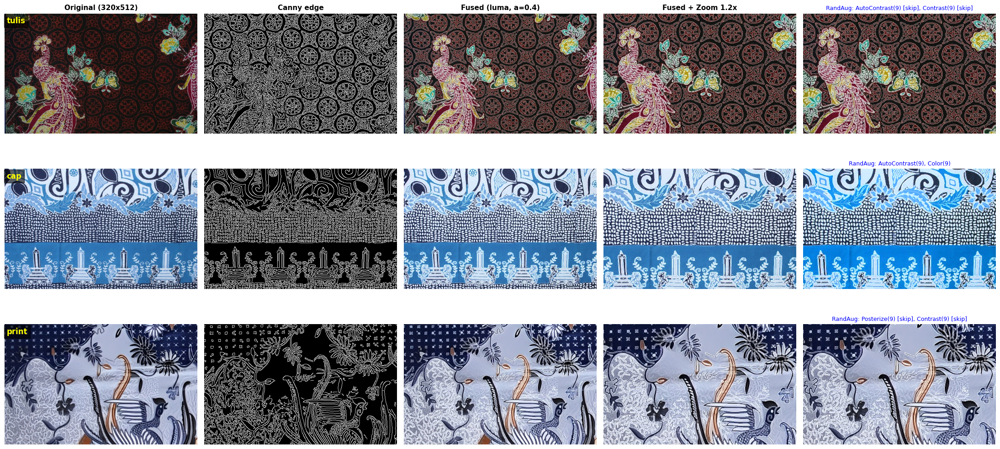

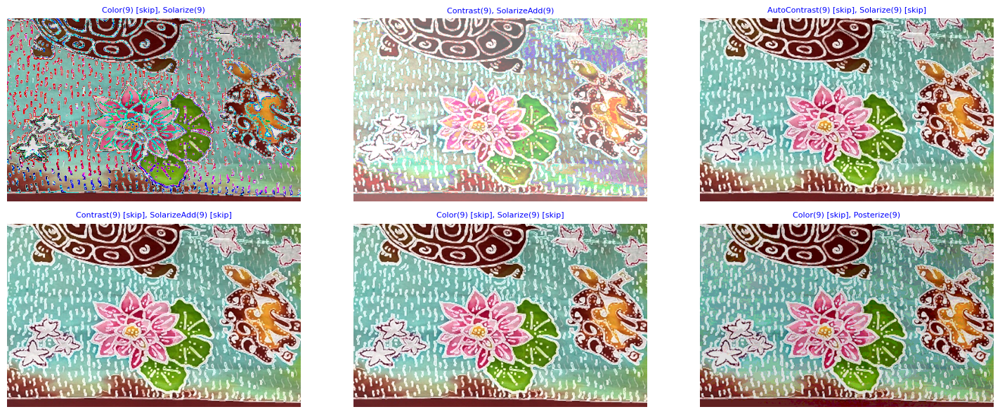

Tensor (3, 320, 512) | min -0.239 | max 1.000 | label 0 (tulis)


In [ ]:
# [4] Preview: 1 citra per kelas, kolom = Original | Canny | Fused | Fused+Zoom | Pipeline latih (Zoom+RandAug)
def to_display(t):
    return ((t.permute(1, 2, 0).cpu().numpy() + 1) / 2).clip(0, 1)

def preview_augmentation(per_class=1, seed=0):
    rng = random.Random(seed)
    chosen = []
    for ci in range(len(CLASSES)):
        chosen += rng.sample(list(np.where(dev_labels == ci)[0]), per_class)
    ds = BatikDataset(dev_paths, dev_labels, train=True)
    fig, axes = plt.subplots(len(chosen), 5, figsize=(22, 3.6 * len(chosen)))
    titles = ["Original (320x512)", "Canny edge", f"Fused ({MODE}, a={ALPHA})", f"Fused + Zoom {ZOOM_FACTOR}x", "Pipeline latih"]
    for r, i in enumerate(chosen):
        raw = ds.load_rgb(i)
        edge = auto_canny(cv2.GaussianBlur(cv2.cvtColor(raw, cv2.COLOR_RGB2GRAY), (3, 3), 0))
        fused = fuse_canny(raw)
        zoomed = zoom_center(fused, ZOOM_FACTOR)
        aug, info = ds.process(i, with_info=True)
        for c, (im, cm) in enumerate(zip([raw, edge, fused, zoomed, aug], [None, "gray", None, None, None])):
            axes[r, c].imshow(im, cmap=cm); axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(titles[c], fontsize=11, fontweight="bold")
        axes[r, 0].text(5, 25, CLASSES[dev_labels[i]], color="yellow", fontsize=12, fontweight="bold",
                        bbox=dict(facecolor="black", alpha=0.6))
        axes[r, 4].set_title(f"RandAug: {info}", fontsize=9, color="blue")
    plt.tight_layout(); plt.show()

def preview_variants(index=0, n=6):
    """Satu citra yang sama dipanggil n kali -> menunjukkan variasi antar epoch."""
    ds = BatikDataset(dev_paths, dev_labels, train=True)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5 * ((n + 1) // 2), 6))
    for ax in axes.ravel():
        im, info = ds.process(index, with_info=True)
        ax.imshow(im); ax.axis("off"); ax.set_title(info, fontsize=8, color="blue")
    plt.tight_layout(); plt.show()

def check_tensor_range():
    x, y = BatikDataset(dev_paths, dev_labels, train=True)[0]
    print(f"Tensor {tuple(x.shape)} | min {x.min():.3f} | max {x.max():.3f} | label {y} ({CLASSES[y]})")

preview_augmentation(per_class=1)
preview_variants(index=0, n=6)
check_tensor_range()

## Arsitektur MSViT (Tabel 3.3, input 320×512)

In [ ]:
# [5] Arsitektur
MSVIT_CONFIGS = {   # attn_dims & block per stage 1..4, MLP ratio 4 (Tabel 3.3)
    "B1": {"dims": [8, 16, 32, 64],    "blocks": [1, 1, 3, 1], "mlp_ratio": 4},
    "B2": {"dims": [8, 16, 32, 128],   "blocks": [1, 1, 3, 1], "mlp_ratio": 4},
    "B3": {"dims": [16, 32, 64, 128],  "blocks": [1, 1, 3, 1], "mlp_ratio": 4},
    "B4": {"dims": [32, 64, 128, 256], "blocks": [1, 1, 3, 1], "mlp_ratio": 4},
}
PATCH_SPECS = [dict(kernel_size=7, stride=4, padding=3)] + [dict(kernel_size=3, stride=2, padding=1)] * 3

class Attention(nn.Module):
    """Self-attention: Q,K,V = W.X ; Attn = softmax(QK^T/sqrt(d)) V  (Persamaan 2-4).
    Memakai F.scaled_dot_product_attention (hasil sama, tapi tidak membuat matriks N x N penuh di memori)."""
    def __init__(self, dim, num_heads=1):
        super().__init__()
        self.h = num_heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4).unbind(0)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(B, N, C))

class Mlp(nn.Module):
    def __init__(self, dim, ratio):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, dim * ratio), nn.GELU(), nn.Linear(dim * ratio, dim)
    def forward(self, x): return self.fc2(self.act(self.fc1(x)))

class Block(nn.Module):
    def __init__(self, dim, ratio, heads=1):
        super().__init__()
        self.n1, self.attn, self.n2, self.mlp = nn.LayerNorm(dim), Attention(dim, heads), nn.LayerNorm(dim), Mlp(dim, ratio)
    def forward(self, x):
        x = x + self.attn(self.n1(x))     # Persamaan 1
        return x + self.mlp(self.n2(x))   # Persamaan 5

class Stage(nn.Module):
    """Patch embedding (konvolusi = downsampling) + Transformer encoder."""
    def __init__(self, cin, dim, depth, ratio, spec, heads=1):
        super().__init__()
        self.proj = nn.Conv2d(cin, dim, **spec)
        self.norm_in = nn.LayerNorm(dim)
        self.blocks = nn.ModuleList([Block(dim, ratio, heads) for _ in range(depth)])
        self.norm_out = nn.LayerNorm(dim)
    def forward(self, x):
        x = self.proj(x); B, C, H, W = x.shape
        x = self.norm_in(x.flatten(2).transpose(1, 2))          # (B, N', C')
        for b in self.blocks: x = b(x)
        x = self.norm_out(x)
        return x.transpose(1, 2).reshape(B, C, H, W)

class MSViT(nn.Module):
    def __init__(self, variant="B1", in_chans=3, num_classes=3, heads=1):
        super().__init__()
        cfg = MSVIT_CONFIGS[variant]
        stages, cin = [], in_chans
        for i in range(4):
            stages.append(Stage(cin, cfg["dims"][i], cfg["blocks"][i], cfg["mlp_ratio"], PATCH_SPECS[i], heads))
            cin = cfg["dims"][i]
        self.stages = nn.ModuleList(stages)
        self.head_norm = nn.LayerNorm(cin)                       # Classifier head: Global pool, Norm, FC(3)
        self.head_fc = nn.Linear(cin, num_classes)
    def forward(self, x):
        for s in self.stages: x = s(x)
        x = x.flatten(2).transpose(1, 2).mean(1)                 # global average pooling
        return self.head_fc(self.head_norm(x))

In [ ]:
# [6] Cek arsitektur: bandingkan dengan Tabel 3.3 dan Gambar 3.5/3.6
@torch.no_grad()
def describe_architecture(variant):
    m = MSViT(variant, num_classes=len(CLASSES)).eval()
    cfg = MSVIT_CONFIGS[variant]
    x = torch.randn(1, 3, IMG_H, IMG_W)
    print(f"\n===== MSViT-{variant} | input 3x{IMG_H}x{IMG_W} =====")
    for i, st in enumerate(m.stages):
        x = st(x); _, C, H, W = x.shape
        k, s = st.proj.kernel_size[0], st.proj.stride[0]
        print(f"Stage {i+1}: kernel {k}, stride {s} | attn dim {cfg['dims'][i]}, MLP ratio {cfg['mlp_ratio']}, "
              f"block {len(st.blocks)} | output {H}x{W}x{C} -> N'={H*W}, C'={C} | params {sum(p.numel() for p in st.parameters()):,}")
    logits = m.head_fc(m.head_norm(x.flatten(2).transpose(1, 2).mean(1)))
    print(f"Classifier head -> logits {tuple(logits.shape)} | total params {sum(p.numel() for p in m.parameters()):,}")

for v in VARIANTS: describe_architecture(v)


===== MSViT-B1 | input 3x320x512 =====
Stage 1: kernel 7, stride 4 | attn dim 8, MLP ratio 4, block 1 | output 80x128x8 -> N'=10240, C'=8 | params 2,088
Stage 2: kernel 3, stride 2 | attn dim 16, MLP ratio 4, block 1 | output 40x64x16 -> N'=2560, C'=16 | params 4,512
Stage 3: kernel 3, stride 2 | attn dim 32, MLP ratio 4, block 3 | output 20x32x32 -> N'=640, C'=32 | params 42,880
Stage 4: kernel 3, stride 2 | attn dim 64, MLP ratio 4, block 1 | output 10x16x64 -> N'=160, C'=64 | params 68,736
Classifier head -> logits (1, 3) | total params 118,539

===== MSViT-B2 | input 3x320x512 =====
Stage 1: kernel 7, stride 4 | attn dim 8, MLP ratio 4, block 1 | output 80x128x8 -> N'=10240, C'=8 | params 2,088
Stage 2: kernel 3, stride 2 | attn dim 16, MLP ratio 4, block 1 | output 40x64x16 -> N'=2560, C'=16 | params 4,512
Stage 3: kernel 3, stride 2 | attn dim 32, MLP ratio 4, block 3 | output 20x32x32 -> N'=640, C'=32 | params 42,880
Stage 4: kernel 3, stride 2 | attn dim 128, MLP ratio 4, bloc

In [ ]:
# [7] Uji memori GPU (stage 1 punya 80x128 = 10240 token). Cari ACCUM_STEPS terkecil yang muat.
def memory_test(variant, micro_batch):
    if device.type != "cuda": print("GPU tidak tersedia"); return
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = MSViT(variant, num_classes=len(CLASSES)).to(device)
    x = torch.randn(micro_batch, 3, IMG_H, IMG_W, device=device)
    with torch.autocast("cuda", dtype=torch.float16):
        loss = model(x).float().mean()
    loss.backward()
    print(f"{variant} micro-batch {micro_batch}: puncak memori {torch.cuda.max_memory_allocated()/1e9:.2f} GB "
          f"(GPU total {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")
    del model, x, loss; torch.cuda.empty_cache()

for mb in [32, 16, 8]:
    try: memory_test("B4", mb)          # B4 = konfigurasi terberat
    except torch.cuda.OutOfMemoryError: print(f"B4 micro-batch {mb}: OOM"); torch.cuda.empty_cache()

B4 micro-batch 32: puncak memori 1.26 GB (GPU total 15.6 GB)
B4 micro-batch 16: puncak memori 0.65 GB (GPU total 15.6 GB)
B4 micro-batch 8: puncak memori 0.34 GB (GPU total 15.6 GB)


## Stratified 5-Fold Cross Validation
Per fold: model baru → 100 epoch (AdamW, cosine annealing, label smoothing 0.1) → bobot dibekukan → validasi (F1 macro, accuracy).
Hasil tiap fold disimpan ke Drive, jadi bisa dilanjutkan jika sesi Colab terputus.

In [ ]:
# [8] Fold (dibuat SEKALI, dipakai sama untuk B1-B4 agar perbandingan adil)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(dev_paths, dev_labels))
for f, (tr, va) in enumerate(folds):
    print(f"Fold {f+1}: latih {len(tr)} {np.bincount(dev_labels[tr]).tolist()} | validasi {len(va)} {np.bincount(dev_labels[va]).tolist()}")
assert all(len(set(tr) & set(va)) == 0 for tr, va in folds), "Ada kebocoran latih/validasi!"

Fold 1: latih 485 [145, 178, 162] | validasi 122 [37, 44, 41]
Fold 2: latih 485 [145, 178, 162] | validasi 122 [37, 44, 41]
Fold 3: latih 486 [146, 177, 163] | validasi 121 [36, 45, 40]
Fold 4: latih 486 [146, 177, 163] | validasi 121 [36, 45, 40]
Fold 5: latih 486 [146, 178, 162] | validasi 121 [36, 44, 41]


In [ ]:
# [9] Fungsi pelatihan satu fold
def train_one_fold(variant, tr_idx, va_idx, fold, epochs=EPOCHS):
    set_seed(SEED + fold)
    micro = BATCH_SIZE // ACCUM_STEPS
    ds_tr = BatikDataset(dev_paths[tr_idx], dev_labels[tr_idx], train=True)    # dengan augmentasi
    ds_va = BatikDataset(dev_paths[va_idx], dev_labels[va_idx], train=False)   # tanpa augmentasi
    dl_tr = DataLoader(ds_tr, batch_size=micro, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True,
                       persistent_workers=NUM_WORKERS > 0)
    dl_va = DataLoader(ds_va, batch_size=micro, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    model = MSViT(variant, num_classes=len(CLASSES)).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    pbar = tqdm(range(1, epochs + 1), desc=f"{variant} fold {fold+1}")
    for epoch in pbar:
        model.train(); optimizer.zero_grad(set_to_none=True); run_loss, n = 0.0, 0
        for it, (x, y) in enumerate(dl_tr):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                loss = criterion(model(x), y)
            scaler.scale(loss / ACCUM_STEPS).backward()
            if (it + 1) % ACCUM_STEPS == 0 or it + 1 == len(dl_tr):
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
            run_loss += loss.item() * len(y); n += len(y)
        scheduler.step()
        pbar.set_postfix(loss=f"{run_loss / n:.4f}", lr=f"{scheduler.get_last_lr()[0]:.2e}")

    # Bobot dibekukan -> validasi (hanya SEKALI setelah epoch terakhir, sesuai Gambar 3.6)
    model.eval()
    for p in model.parameters(): p.requires_grad_(False)
    preds, gts = [], []
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        for x, y in dl_va:
            preds += model(x.to(device)).argmax(1).cpu().tolist(); gts += y.tolist()
    res = {"f1_macro": float(f1_score(gts, preds, average="macro")), "accuracy": float(accuracy_score(gts, preds)),
           "train_loss_final": run_loss / n}
    del model, optimizer, dl_tr, dl_va; torch.cuda.empty_cache()
    return res

In [ ]:
# [10] (Opsional) Uji cepat: 1 fold, 1 epoch, B1 -> pastikan pipeline jalan & ukur waktu. Hasil TIDAK disimpan.
t0 = time.time()
print(train_one_fold("B1", *folds[0], fold=0, epochs=1))
print(f"Waktu 1 epoch B1: {time.time() - t0:.1f} dtk -> perkiraan 100 epoch x 5 fold: {(time.time() - t0) * 500 / 3600:.1f} jam (per konfigurasi, kasar)")

B1 fold 1:   0%|          | 0/1 [00:00<?, ?it/s]

{'f1_macro': 0.42833666444592494, 'accuracy': 0.4344262295081967, 'train_loss_final': 1.1475144457571285}
Waktu 1 epoch B1: 221.6 dtk -> perkiraan 100 epoch x 5 fold: 30.8 jam (per konfigurasi, kasar)


In [ ]:
# [11] Cross validation penuh (resume otomatis dari cv_results.json)
def load_results():
    return json.load(open(RESULT_FILE)) if RESULT_FILE.exists() else {}

def run_cross_validation(variants=VARIANTS):
    results = load_results()
    for v in variants:
        for f, (tr, va) in enumerate(folds):
            key = f"{v}_fold{f+1}"
            if key in results:
                print(f"[skip] {key} sudah selesai: {results[key]}"); continue
            t0 = time.time()
            results[key] = train_one_fold(v, tr, va, fold=f)
            json.dump(results, open(RESULT_FILE, "w"), indent=2)
            print(f"[selesai] {key}: {results[key]} ({(time.time() - t0) / 60:.1f} menit)")
    return results

results = run_cross_validation()   # bisa diganti run_cross_validation(["B1"]) untuk satu konfigurasi dulu

[skip] B1_fold1 sudah selesai: {'f1_macro': 0.8368887129111124, 'accuracy': 0.8360655737704918, 'train_loss_final': 0.6384122662323037}
[skip] B1_fold2 sudah selesai: {'f1_macro': 0.777988977988978, 'accuracy': 0.7786885245901639, 'train_loss_final': 0.5549186230934773}
[skip] B1_fold3 sudah selesai: {'f1_macro': 0.817015864042681, 'accuracy': 0.8181818181818182, 'train_loss_final': 0.5829352640811308}
[skip] B1_fold4 sudah selesai: {'f1_macro': 0.8674534385801991, 'accuracy': 0.8677685950413223, 'train_loss_final': 0.5556452433758803}
[skip] B1_fold5 sudah selesai: {'f1_macro': 0.830460254545502, 'accuracy': 0.8347107438016529, 'train_loss_final': 0.5584096611772545}
[skip] B2_fold1 sudah selesai: {'f1_macro': 0.7185010069170826, 'accuracy': 0.7213114754098361, 'train_loss_final': 0.5028800217146726}
[skip] B2_fold2 sudah selesai: {'f1_macro': 0.7602744211939614, 'accuracy': 0.7704918032786885, 'train_loss_final': 0.48106460767922943}
[skip] B2_fold3 sudah selesai: {'f1_macro': 0.8361

In [ ]:
# [12] Ringkasan: rata-rata ± std (5 fold) per konfigurasi, lalu pilih yang terbaik
import pandas as pd

def summarize(results):
    rows = []
    for v in VARIANTS:
        r = [results[f"{v}_fold{f+1}"] for f in range(N_FOLDS) if f"{v}_fold{f+1}" in results]
        if len(r) == 0: continue
        f1s, accs = np.array([x["f1_macro"] for x in r]), np.array([x["accuracy"] for x in r])
        rows.append({"Konfigurasi": v, "Fold selesai": len(r),
                     "F1 macro": f"{f1s.mean():.4f} ± {f1s.std(ddof=1) if len(r) > 1 else 0:.4f}",
                     "Accuracy": f"{accs.mean():.4f} ± {accs.std(ddof=1) if len(r) > 1 else 0:.4f}",
                     "_f1": f1s.mean(), "_acc": accs.mean()})
    df = pd.DataFrame(rows)
    best = df.sort_values(["_f1", "_acc"], ascending=False).iloc[0]["Konfigurasi"]
    print(df.drop(columns=["_f1", "_acc"]).to_string(index=False))
    print(f"\nKonfigurasi terbaik (rata-rata F1 macro tertinggi): {best}")
    return df, best

df_cv, best_variant = summarize(load_results())

Konfigurasi  Fold selesai        F1 macro        Accuracy
         B1             5 0.8260 ± 0.0326 0.8271 ± 0.0325
         B2             5 0.7706 ± 0.0450 0.7744 ± 0.0428
         B3             5 0.7756 ± 0.0659 0.7793 ± 0.0599
         B4             5 0.8022 ± 0.0438 0.8040 ± 0.0410

Konfigurasi terbaik (rata-rata F1 macro tertinggi): B1


# Tambahan: Prediksi per Fold, Confusion Matrix, dan Cek Duplikat
**Analisis Permasalah** Menampilkan citra yang salah di prediks dan confussion metri, serta mengecek duplikat data

In [ ]:
# [T1] Versi train_one_fold yang juga menyimpan prediksi (pengaturan training sama persis dengan sel 9)
from sklearn.metrics import confusion_matrix, classification_report

def train_one_fold_v2(variant, tr_idx, va_idx, fold, epochs=EPOCHS):
    set_seed(SEED + fold)
    micro = BATCH_SIZE // ACCUM_STEPS
    ds_tr = BatikDataset(dev_paths[tr_idx], dev_labels[tr_idx], train=True)
    ds_va = BatikDataset(dev_paths[va_idx], dev_labels[va_idx], train=False)
    dl_tr = DataLoader(ds_tr, batch_size=micro, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True,
                       persistent_workers=NUM_WORKERS > 0)
    dl_va = DataLoader(ds_va, batch_size=micro, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    model = MSViT(variant, num_classes=len(CLASSES)).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    pbar = tqdm(range(1, epochs + 1), desc=f"{variant} fold {fold+1}")
    for epoch in pbar:
        model.train(); optimizer.zero_grad(set_to_none=True); run_loss, n = 0.0, 0
        for it, (x, y) in enumerate(dl_tr):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                loss = criterion(model(x), y)
            scaler.scale(loss / ACCUM_STEPS).backward()
            if (it + 1) % ACCUM_STEPS == 0 or it + 1 == len(dl_tr):
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
            run_loss += loss.item() * len(y); n += len(y)
        scheduler.step()
        pbar.set_postfix(loss=f"{run_loss / n:.4f}")

    model.eval()
    for p in model.parameters(): p.requires_grad_(False)
    preds, gts = [], []
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        for x, y in dl_va:                      # shuffle=False -> urutan sama dengan va_idx
            preds += model(x.to(device)).argmax(1).cpu().tolist(); gts += y.tolist()
    res = {"f1_macro": float(f1_score(gts, preds, average="macro")), "accuracy": float(accuracy_score(gts, preds)),
           "train_loss_final": run_loss / n,
           "val_paths": [str(p) for p in dev_paths[va_idx]], "y_true": gts, "y_pred": preds}
    del model, optimizer, dl_tr, dl_va; torch.cuda.empty_cache()
    return res

def run_cv_with_preds(variants=("B1",), tag="baseline"):
    """tag = nama eksperimen. Ganti tag setiap kali pengaturan diubah supaya hasil tidak tercampur."""
    pred_file = RESULT_DIR / f"cv_preds_{tag}.json"
    results = json.load(open(pred_file)) if pred_file.exists() else {}
    for v in variants:
        for f, (tr, va) in enumerate(folds):
            key = f"{v}_fold{f+1}"
            if key in results:
                print(f"[skip] {key}"); continue
            t0 = time.time()
            results[key] = train_one_fold_v2(v, tr, va, fold=f)
            json.dump(results, open(pred_file, "w"))
            r = results[key]
            print(f"[selesai] {key}: F1 {r['f1_macro']:.4f} | acc {r['accuracy']:.4f} ({(time.time()-t0)/60:.1f} menit)")
    return results

In [ ]:
# [T2] Jalankan CV (B1 saja dulu). Hasil sedikit berbeda dari cv_results.json lama karena ada unsur acak (augmentasi, AMP).
preds_baseline = run_cv_with_preds(["B1"], tag="baseline")

[skip] B1_fold1
[skip] B1_fold2
[skip] B1_fold3
[skip] B1_fold4
[skip] B1_fold5


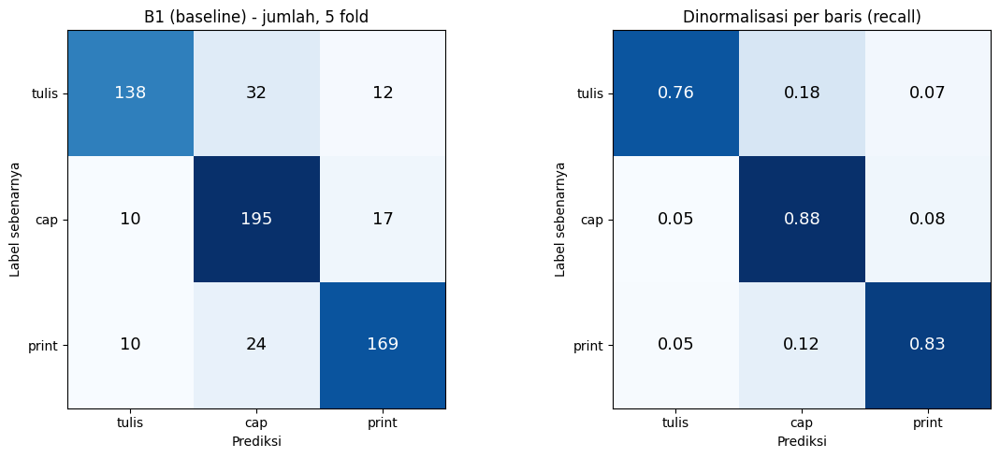

              precision    recall  f1-score   support

       tulis     0.8734    0.7582    0.8118       182
         cap     0.7769    0.8784    0.8245       222
       print     0.8535    0.8325    0.8429       203

    accuracy                         0.8270       607
   macro avg     0.8346    0.8230    0.8264       607
weighted avg     0.8315    0.8270    0.8268       607

Recall per kelas di tiap fold:
  B1_fold1: {'tulis': 0.811, 'cap': 0.841, 'print': 0.854}
  B1_fold2: {'tulis': 0.676, 'cap': 0.932, 'print': 0.707}
  B1_fold3: {'tulis': 0.722, 'cap': 0.822, 'print': 0.9}
  B1_fold4: {'tulis': 0.861, 'cap': 0.889, 'print': 0.85}
  B1_fold5: {'tulis': 0.722, 'cap': 0.909, 'print': 0.854}


In [ ]:
# [T3] Confusion matrix gabungan 5 fold + metrik per kelas
def load_preds(tag, variant):
    res = json.load(open(RESULT_DIR / f"cv_preds_{tag}.json"))
    keys = [f"{variant}_fold{f+1}" for f in range(N_FOLDS) if f"{variant}_fold{f+1}" in res]
    return res, keys

def plot_cm(cm, title, ax, fmt):
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya"); ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)

def analyze_cv(tag="baseline", variant="B1"):
    res, keys = load_preds(tag, variant)
    y_true = sum([res[k]["y_true"] for k in keys], [])
    y_pred = sum([res[k]["y_pred"] for k in keys], [])
    labels = list(range(len(CLASSES)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    plot_cm(cm, f"{variant} ({tag}) - jumlah, {len(keys)} fold", axes[0], "d")
    plot_cm(cm_norm, "Dinormalisasi per baris (recall)", axes[1], ".2f")
    plt.tight_layout(); plt.show()
    print(classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, digits=4))
    print("Recall per kelas di tiap fold:")
    for k in keys:
        yt, yp = np.array(res[k]["y_true"]), np.array(res[k]["y_pred"])
        rec = {CLASSES[c]: round(float((yp[yt == c] == c).mean()), 3) for c in labels}
        print(f"  {k}: {rec}")

analyze_cv("baseline", "B1")

Total salah: 105


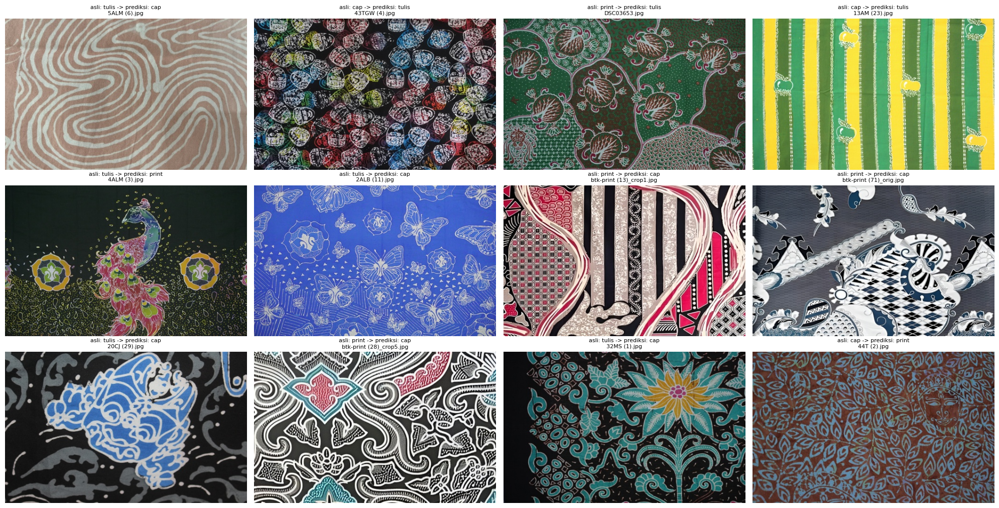

In [ ]:
# [T4] Lihat citra yang salah diprediksi (apakah ada pola: latar, sumber foto, motif?)
def show_misclassified(tag="baseline", variant="B1", max_n=12, seed=0):
    res, keys = load_preds(tag, variant)
    wrong = []
    for k in keys:
        for p, t, q in zip(res[k]["val_paths"], res[k]["y_true"], res[k]["y_pred"]):
            if t != q: wrong.append((p, t, q))
    print(f"Total salah: {len(wrong)}")
    random.Random(seed).shuffle(wrong)
    wrong = wrong[:max_n]
    cols = 4; rows = (len(wrong) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.4 * rows))
    for ax in np.array(axes).ravel(): ax.axis("off")
    for ax, (p, t, q) in zip(np.array(axes).ravel(), wrong):
        ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        ax.set_title(f"asli: {CLASSES[t]} -> prediksi: {CLASSES[q]}\n{Path(p).name}", fontsize=8)
    plt.tight_layout(); plt.show()

show_misclassified("baseline", "B1")

## Cek Citra Duplikat / Hampir Kembar
Memakai difference hash (dHash 64 bit). Menangkap foto yang nyaris identik (file ganda, foto diulang), bukan kain yang sama dari sudut berbeda.

hash train:   0%|          | 0/607 [00:00<?, ?it/s]

Pasangan hampir kembar di data pengembangan: 3
  - berada di fold berbeda (berpotensi bocor latih->validasi): 3
  - beda kelas (label berpotensi salah): 0
 tulis: 45 citra
   cap: 56 citra
 print: 51 citra


hash test:   0%|          | 0/152 [00:00<?, ?it/s]

Pasangan hampir kembar antara train dan test: 1  (idealnya 0)


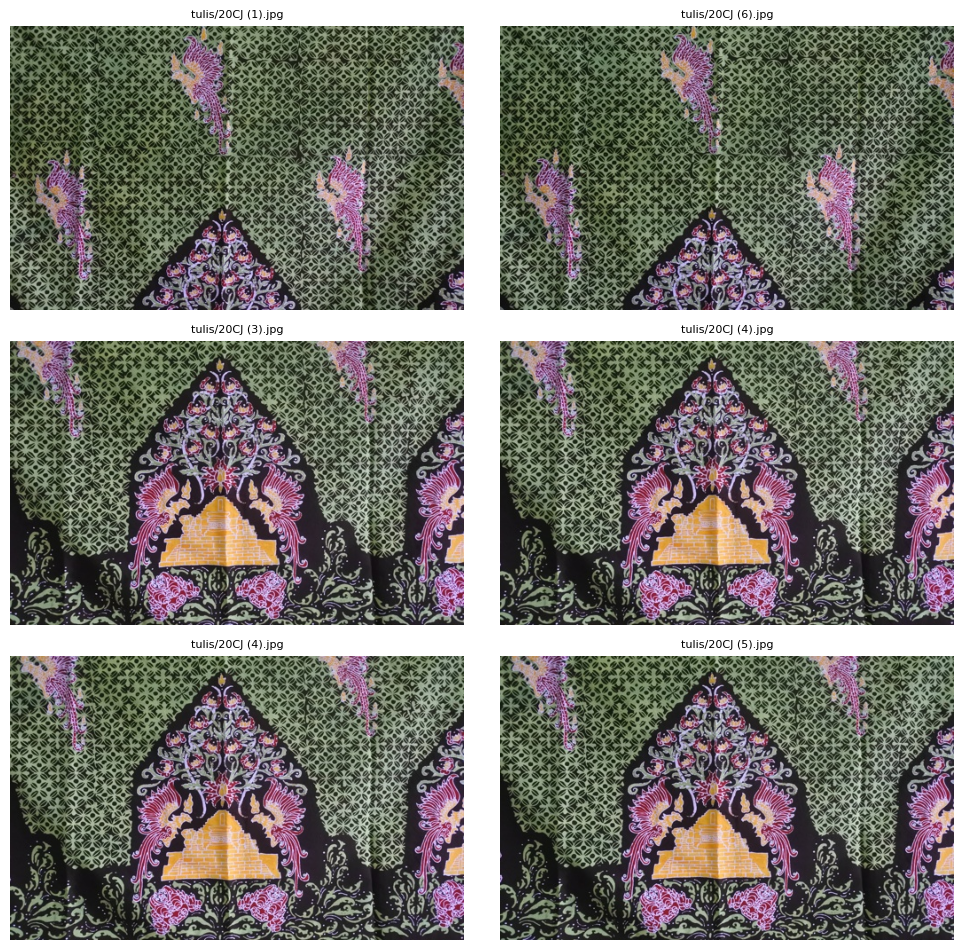

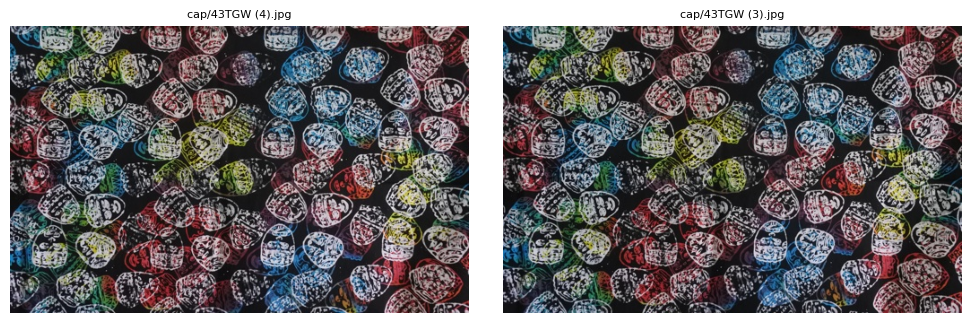

In [ ]:
# [T5] Duplikat di data pengembangan (antar fold) dan antara pengembangan vs test
def dhash(path):
    g = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

THRESH = 4      # jarak Hamming maksimum (dari 64 bit) yang dianggap hampir kembar
h_dev = np.array([dhash(p) for p in tqdm(dev_paths, desc="hash train")])
fold_of = np.zeros(len(dev_paths), dtype=int)
for f, (_, va) in enumerate(folds): fold_of[va] = f

d = (h_dev[:, None, :] != h_dev[None, :, :]).sum(2)
ii, jj = np.where(np.triu(d <= THRESH, k=1))
cross = [(i, j) for i, j in zip(ii, jj) if fold_of[i] != fold_of[j]]
diff_cls = [(i, j) for i, j in zip(ii, jj) if dev_labels[i] != dev_labels[j]]
print(f"Pasangan hampir kembar di data pengembangan: {len(ii)}")
print(f"  - berada di fold berbeda (berpotensi bocor latih->validasi): {len(cross)}")
print(f"  - beda kelas (label berpotensi salah): {len(diff_cls)}")

test_paths, test_labels = list_images(SPLIT_DIR / "test", CLASSES)
h_te = np.array([dhash(p) for p in tqdm(test_paths, desc="hash test")])
d2 = (h_dev[:, None, :] != h_te[None, :, :]).sum(2)
a, b = np.where(d2 <= THRESH)
print(f"Pasangan hampir kembar antara train dan test: {len(a)}  (idealnya 0)")

def show_pairs(pairs, pa, pb, n=4):
    if len(pairs) == 0: return
    fig, axes = plt.subplots(len(pairs[:n]), 2, figsize=(10, 3.2 * len(pairs[:n])))
    axes = np.atleast_2d(axes)
    for r, (i, j) in enumerate(pairs[:n]):
        for c, p in enumerate([pa[i], pb[j]]):
            axes[r, c].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
            axes[r, c].set_title(Path(p).parent.name + "/" + Path(p).name, fontsize=8)
    plt.tight_layout(); plt.show()

show_pairs(cross, dev_paths, dev_paths)                         # contoh duplikat antar fold
show_pairs(list(zip(a, b)), dev_paths, test_paths)              # contoh duplikat train vs test

In [ ]:
# [F1] Pindahkan 1 citra near-duplicate dari test/ (dipindah, bukan dihapus). Jalankan SETELAH sel T5.
import shutil
removed_dir = SPLIT_DIR / "test_removed"; removed_dir.mkdir(exist_ok=True)
for i_test in sorted(set(b.tolist())):            # b = indeks test yang mirip train (dari sel T5)
    p = Path(test_paths[i_test])
    print("Pindah:", p)
    shutil.move(str(p), str(removed_dir / f"{p.parent.name}__{p.name}"))

Pindah: /content/drive/MyDrive/SKRIPSIIIII/btk/dataset/dataset_batik_split/test/cap/43TGW (3).jpg


#Percobaan 1
remove invert and equal hist on randaugment param

In [ ]:
_ = run_cv_with_preds(["B1", "B4"], tag="tanpa_invert_equalize")

[skip] 'B1_fold1': {'f1_macro': 0.7783437610966906, 'accuracy': 0.7786885245901639, 'train_loss_final': 0.5052507854614061}
[skip] 'B1_fold2': {'f1_macro': 0.791079083772943, 'accuracy': 0.7950819672131147, 'train_loss_final': 0.49996201918297206}
[skip] 'B1_fold3': {'f1_macro': 0.8846670963940214, 'accuracy': 0.8842975206611571, 'train_loss_final': 0.4514190716507994}
[skip] 'B1_fold4': {'f1_macro': 0.8686718482521091, 'accuracy': 0.8677685950413223, 'train_loss_final': 0.4507033755013972}
[skip] 'B1_fold5': {'f1_macro': 0.8394816056106379, 'accuracy': 0.8429752066115702, 'train_loss_final': 0.4700768364309774}
[skip] 'B4_fold1': {'f1_macro': 0.9024032459425717, 'accuracy': 0.9016393442622951, 'train_loss_final': 0.3339425653526463}
[skip] 'B4_fold2': {'f1_macro': 0.8015502732579805, 'accuracy': 0.8032786885245902, 'train_loss_final': 0.33406955962328566}
[skip] 'B4_fold3': {'f1_macro': 0.7529405190959125, 'accuracy': 0.7603305785123967, 'train_loss_final': 0.3199202556914263}
[skip] 

In [ ]:
def ms(file, v):
    r = json.load(open(file)); f = [x["f1_macro"] for k, x in r.items() if k.startswith(v + "_fold")]
    return f"{np.mean(f):.4f} ± {np.std(f, ddof=1):.4f}"
for v in ["B1", "B4"]:
    print(v, "baseline:", ms(RESULT_DIR/"cv_results.json", v), "| baru:", ms(RESULT_DIR/"cv_preds_tanpa_invert_equalize.json", v))

B1 baseline: 0.8260 ± 0.0326 | baru: 0.8324 ± 0.0467
B4 baseline: 0.8022 ± 0.0438 | baru: 0.8562 ± 0.0742


In [ ]:
_ = run_cv_with_preds(["B2", "B3"], tag="tanpa_invert_equalize")

[skip] 'B2_fold1': {'f1_macro': 0.744135328364719, 'accuracy': 0.7459016393442623, 'train_loss_final': 0.46222790860638174}
[skip] 'B2_fold2': {'f1_macro': 0.7671787868442017, 'accuracy': 0.7786885245901639, 'train_loss_final': 0.4246717774376427}
[skip] 'B2_fold3': {'f1_macro': 0.7913667574325051, 'accuracy': 0.7933884297520661, 'train_loss_final': 0.4135064551369153}
[skip] 'B2_fold4': {'f1_macro': 0.7505229481973669, 'accuracy': 0.7520661157024794, 'train_loss_final': 0.45376876855092774}
[skip] 'B2_fold5': {'f1_macro': 0.7764627845273008, 'accuracy': 0.7768595041322314, 'train_loss_final': 0.44473542450877374}
[skip] 'B3_fold1': {'f1_macro': 0.9015356820234869, 'accuracy': 0.9016393442622951, 'train_loss_final': 0.38053109719581213}
[skip] 'B3_fold2': {'f1_macro': 0.7311723052714397, 'accuracy': 0.7377049180327869, 'train_loss_final': 0.36265769465682435}
[skip] 'B3_fold3': {'f1_macro': 0.7685313170693288, 'accuracy': 0.768595041322314, 'train_loss_final': 0.3815551389146734}
[skip

In [ ]:
def ms(file, v):
    r = json.load(open(file)); f = [x["f1_macro"] for k, x in r.items() if k.startswith(v + "_fold")]
    return f"{np.mean(f):.4f} ± {np.std(f, ddof=1):.4f}"
for v in ["B1","B2", "B3","B4"]:
    print(v, "baseline:", ms(RESULT_DIR/"cv_results.json", v), "| baru:", ms(RESULT_DIR/"cv_preds_tanpa_invert_equalize.json", v))

B1 baseline: 0.8260 ± 0.0326 | baru: 0.8324 ± 0.0467
B2 baseline: 0.7706 ± 0.0450 | baru: 0.7659 ± 0.0192
B3 baseline: 0.7756 ± 0.0659 | baru: 0.8328 ± 0.0774
B4 baseline: 0.8022 ± 0.0438 | baru: 0.8562 ± 0.0742


#Percobaan 2
remove invert, equal hist, & brightness on randaugment param

In [ ]:
_ = run_cv_with_preds(["B1", "B4"], tag="tanpa_invert_equalize_brightness")

[skip] 'B1_fold1': {'f1_macro': 0.7942028985507248, 'accuracy': 0.7950819672131147, 'train_loss_final': 0.49956392615111833}
[skip] 'B1_fold2': {'f1_macro': 0.850829605659719, 'accuracy': 0.8524590163934426, 'train_loss_final': 0.46331627553271265}
[skip] 'B1_fold3': {'f1_macro': 0.8676046176046176, 'accuracy': 0.8677685950413223, 'train_loss_final': 0.4659053289595945}
[skip] 'B1_fold4': {'f1_macro': 0.8754681647940075, 'accuracy': 0.8760330578512396, 'train_loss_final': 0.43350998450208594}
[skip] 'B1_fold5': {'f1_macro': 0.8435490435490435, 'accuracy': 0.8429752066115702, 'train_loss_final': 0.4784286848802135}
[skip] 'B4_fold1': {'f1_macro': 0.8458772896656694, 'accuracy': 0.8442622950819673, 'train_loss_final': 0.3390310832520121}
[skip] 'B4_fold2': {'f1_macro': 0.7467201283079391, 'accuracy': 0.7704918032786885, 'train_loss_final': 0.32735742109338034}
[skip] 'B4_fold3': {'f1_macro': 0.9092592592592593, 'accuracy': 0.9090909090909091, 'train_loss_final': 0.32710072704793985}
[ski

In [ ]:
def ms(file, v):
    r = json.load(open(file)); f = [x["f1_macro"] for k, x in r.items() if k.startswith(v + "_fold")]
    return f"{np.mean(f):.4f} ± {np.std(f, ddof=1):.4f}"
for v in ["B1", "B4"]:
    print(v, "baseline:", ms(RESULT_DIR/"cv_results.json", v), "| baru:", ms(RESULT_DIR/"cv_preds_tanpa_invert_equalize_brightness.json", v))

B1 baseline: 0.8260 ± 0.0326 | baru: 0.8463 ± 0.0318
B4 baseline: 0.8022 ± 0.0438 | baru: 0.8440 ± 0.0620


# Train Seluruh Data

## Konfigurasi B1

In [ ]:
# [F2] Train ulang pada SELURUH train/, tanpa fold. Simpan checkpoint epoch terakhir saja.
FINAL_DIR = RESULT_DIR / "final"; FINAL_DIR.mkdir(exist_ok=True)

def train_final(variant, tag, seed=SEED, epochs=EPOCHS):
    set_seed(seed)
    print("Operasi RandAugment aktif:", aa._RAND_TRANSFORMS)   # cek: tanpa Invert & Equalize
    micro = BATCH_SIZE // ACCUM_STEPS
    ds = BatikDataset(dev_paths, dev_labels, train=True)
    dl = DataLoader(ds, batch_size=micro, shuffle=True, num_workers=NUM_WORKERS,
                    pin_memory=True, persistent_workers=NUM_WORKERS > 0)
    model = MSViT(variant, num_classes=len(CLASSES)).to(device)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    for epoch in tqdm(range(1, epochs + 1), desc=f"{variant} final"):
        model.train(); opt.zero_grad(set_to_none=True)
        for it, (x, y) in enumerate(dl):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                loss = crit(model(x), y)
            scaler.scale(loss / ACCUM_STEPS).backward()
            if (it + 1) % ACCUM_STEPS == 0 or it + 1 == len(dl):
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        sch.step()
    ckpt = FINAL_DIR / f"msvit_{variant}_{tag}_seed{seed}.pt"
    torch.save(model.state_dict(), ckpt); print("Tersimpan:", ckpt)
    return model

model_final = train_final("B1", tag="run1")

Operasi RandAugment aktif: ['AutoContrast', 'Posterize', 'Solarize', 'SolarizeAdd', 'Color', 'Contrast', 'Sharpness']


B1 final:   0%|          | 0/100 [00:00<?, ?it/s]

Tersimpan: /content/drive/MyDrive/SKRIPSIIIII/btk/dataset/hasil_cv_msvit/final/msvit_B1_run1_seed42.pt


 tulis: 45 citra
   cap: 55 citra
 print: 51 citra


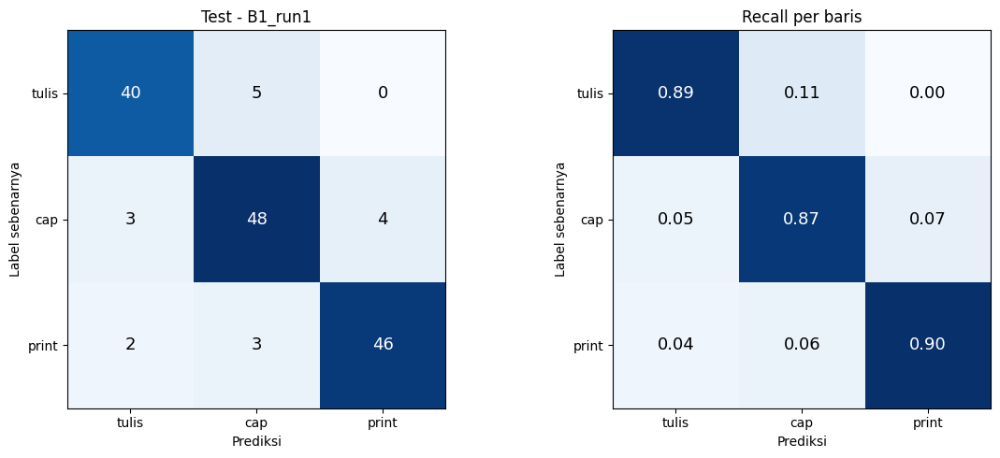

              precision    recall  f1-score   support

       tulis     0.8889    0.8889    0.8889        45
         cap     0.8571    0.8727    0.8649        55
       print     0.9200    0.9020    0.9109        51

    accuracy                         0.8874       151
   macro avg     0.8887    0.8879    0.8882       151
weighted avg     0.8878    0.8874    0.8876       151



In [ ]:
# [F3] Evaluasi di test SEKALI per model (confusion matrix + metrik per kelas)
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

def plot_cm(cm, title, ax, fmt):
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya"); ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)

@torch.no_grad()
def eval_test(model, tag):
    tp, tl = list_images(SPLIT_DIR / "test", CLASSES)
    dl = DataLoader(BatikDataset(tp, tl, train=False), batch_size=16, shuffle=False, num_workers=NUM_WORKERS)
    model.eval(); preds, gts = [], []
    for x, y in dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); gts += y.tolist()
    labels = list(range(len(CLASSES)))
    cm = confusion_matrix(gts, preds, labels=labels)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    plot_cm(cm, f"Test - {tag}", axes[0], "d")
    plot_cm(cm / cm.sum(1, keepdims=True), "Recall per baris", axes[1], ".2f")
    plt.tight_layout(); plt.show()
    print(classification_report(gts, preds, labels=labels, target_names=CLASSES, digits=4))
    json.dump({"tag": tag, "acc": float(accuracy_score(gts, preds)),
               "f1_macro": float(f1_score(gts, preds, average="macro")),
               "cm": cm.tolist(), "paths": tp.tolist(), "y_true": gts, "y_pred": preds},
              open(FINAL_DIR / f"test_{tag}.json", "w"), indent=2)

eval_test(model_final, "B1_run1")

## Konfigurasi B4

Operasi RandAugment aktif: ['AutoContrast', 'Posterize', 'Solarize', 'SolarizeAdd', 'Color', 'Contrast', 'Sharpness']


B4 final:   0%|          | 0/100 [00:00<?, ?it/s]

Tersimpan: /content/drive/MyDrive/SKRIPSIIIII/btk/dataset/hasil_cv_msvit/final/msvit_B4_run1_seed42.pt


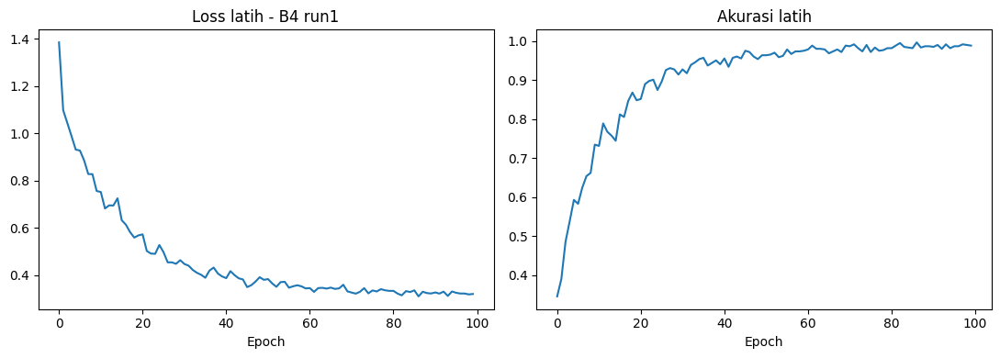

In [ ]:
# [F2 v2] Train ulang pada SELURUH train/, tanpa fold. Log loss & akurasi LATIH per epoch.
# Tidak ada evaluasi val/test selama training; checkpoint = epoch terakhir.
FINAL_DIR = RESULT_DIR / "final"; FINAL_DIR.mkdir(exist_ok=True)

def train_final(variant, tag, seed=SEED, epochs=EPOCHS):
    set_seed(seed)
    print("Operasi RandAugment aktif:", aa._RAND_TRANSFORMS)   # cek: tanpa Invert & Equalize
    micro = BATCH_SIZE // ACCUM_STEPS
    ds = BatikDataset(dev_paths, dev_labels, train=True)
    dl = DataLoader(ds, batch_size=micro, shuffle=True, num_workers=NUM_WORKERS,
                    pin_memory=True, persistent_workers=NUM_WORKERS > 0)
    model = MSViT(variant, num_classes=len(CLASSES)).to(device)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    hist = {"loss": [], "acc": [], "lr": []}
    pbar = tqdm(range(1, epochs + 1), desc=f"{variant} final")
    for epoch in pbar:
        model.train(); opt.zero_grad(set_to_none=True)
        run_loss, correct, n = 0.0, 0, 0
        for it, (x, y) in enumerate(dl):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss / ACCUM_STEPS).backward()
            if (it + 1) % ACCUM_STEPS == 0 or it + 1 == len(dl):
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            run_loss += loss.item() * len(y); n += len(y)
            correct += (out.argmax(1) == y).sum().item()
        hist["lr"].append(sch.get_last_lr()[0]); sch.step()
        hist["loss"].append(run_loss / n); hist["acc"].append(correct / n)
        pbar.set_postfix(loss=f"{hist['loss'][-1]:.4f}", acc=f"{hist['acc'][-1]:.3f}")

    ckpt = FINAL_DIR / f"msvit_{variant}_{tag}_seed{seed}.pt"
    torch.save(model.state_dict(), ckpt); print("Tersimpan:", ckpt)
    json.dump(hist, open(FINAL_DIR / f"train_log_{variant}_{tag}.json", "w"), indent=2)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["loss"]); ax[0].set_title(f"Loss latih - {variant} {tag}"); ax[0].set_xlabel("Epoch")
    ax[1].plot(hist["acc"]);  ax[1].set_title("Akurasi latih"); ax[1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(FINAL_DIR / f"train_curve_{variant}_{tag}.png", dpi=150); plt.show()
    return model

model_final = train_final("B4", tag="run1")

 tulis: 45 citra
   cap: 55 citra
 print: 51 citra


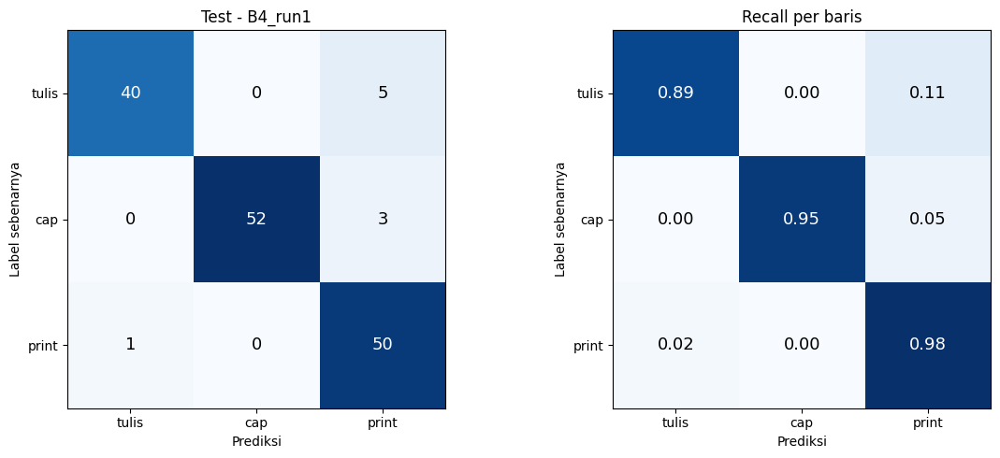

              precision    recall  f1-score   support

       tulis     0.9756    0.8889    0.9302        45
         cap     1.0000    0.9455    0.9720        55
       print     0.8621    0.9804    0.9174        51

    accuracy                         0.9404       151
   macro avg     0.9459    0.9382    0.9399       151
weighted avg     0.9461    0.9404    0.9411       151



In [ ]:
# [F3 v2] Evaluasi model B4 di test set SEKALI (confusion matrix + metrik per kelas)
eval_test(model_final, "B4_run1")